# Example: RMDC26_001422 — a blind Roman event with a close/wide degeneracy

This is the second blind example on simulated Roman data, after `example_rmdc26_000026`. That event had a single
sharp solution. This one shows the other common case: a planetary anomaly at the peak of a high-magnification event,
where two different lens geometries describe the data almost equally well, and the map has two valleys.

**The data.** RMDC26_001422 is an event of the *Experienced tier* of the Roman Microlensing Data Challenge 2026
(Roman Galactic Exoplanet Survey Project Infrastructure Team, RGES-PIT; public domain, CC0,
[huggingface.co/datasets/RGES-PIT/Experienced](https://huggingface.co/datasets/RGES-PIT/Experienced)). Its light
curves were simulated with GULLS (Penny et al. 2019): six seasons over 4.7 years, one F146 exposure every 12 minutes,
F087 and F213 every few hours. Experienced-tier events may contain up to two sources and four lens bodies, orbital
motion, parallax, and spotted (variable) sources; the true parameters are not published, so this is a **blind**
analysis. I picked the event from 251 screened events of the tier: it peaks well inside a season, has a short
timescale and a quiet baseline, and a single lens leaves a sharp, structured residual right at the peak.

**What this notebook does.**

1. It loads the photometry (49 488 points) and reduces it to 1558 points for the maps (Sections 1 and 2).
2. It fits a single lens and then binary lenses from guided starts for a central-caustic anomaly (Sections 3 and 4).
3. It maps Δχ²(log *s*, log *q*) over −1 ≤ log *s* ≤ 1, −5 ≤ log *q* ≤ 0, and zooms into the valleys at 4×, 32× and
   64× (Sections 5 and 6).
4. It polishes the two solutions, compares their light curves and caustics, and interprets the system (Sections 7–10).

**Runtime.** The coarse map took 23 minutes on a 14-core Intel Core i5-13500 (20 threads), the zoom boxes 23, 2, 2 and
0.6 minutes, the guided fits 4 and the polish a few minutes. Everything is stored in `data/`, so the notebook runs in
about a minute by default. Set `RECOMPUTE = True` to compute it all again (about an hour on a 20-thread desktop).

## 0. Setup

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import figures, caustics, model

RECOMPUTE = False              # True: compute all maps and fits again (about an hour on a 20-thread desktop)
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/rmdc1422_photometry.csv` holds all points of the event (none is saturated): `set` (filter `F087`, `F146` or
`F213`), `t` (BJD − 2460000), and `flux`, `flux_err` in micro-Jansky as provided by the challenge. The magnitudes
below are AB magnitudes, 23.9 − 2.5 log₁₀(flux / µJy).

In [2]:
SETS = ["F087", "F146", "F213"]
rows = np.genfromtxt("data/rmdc1422_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
sel = lambda r, n: (r["t"][r["set"] == n], r["flux"][r["set"] == n], r["flux_err"][r["set"] == n])
data_all = lenscape.Data.from_sets({n: sel(rows, n) for n in SETS})
mag = lambda f: 23.9 - 2.5 * np.log10(f)                # AB magnitude of a flux in micro-Jansky
data_all

Data(49488 points, t 1447.76 .. 3164.50, sets {'F087': 1501, 'F146': 46488, 'F213': 1499})

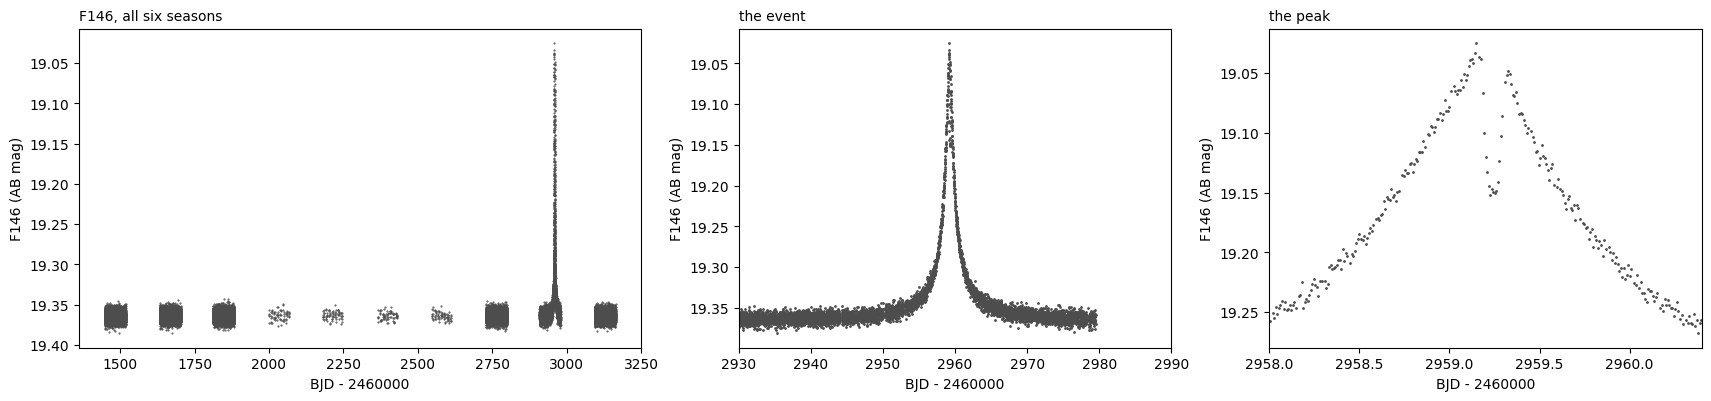

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw=dict(width_ratios=[1.3, 1, 1]), constrained_layout=True)
k = data_all.names.index("F146")
m = data_all.idx == k
axs[0].plot(data_all.t[m], mag(data_all.f[m]), ".", ms=1, color="0.3", rasterized=True)
axs[0].set_title("F146, all six seasons", loc="left", fontsize=10)
for ax, (a, b) in zip(axs[1:], ((2930, 2990), (2958.0, 2960.4))):
    m = (data_all.idx == k) & (data_all.t > a) & (data_all.t < b)
    ax.plot(data_all.t[m], mag(data_all.f[m]), ".", ms=2, color="0.3", rasterized=True)
    ax.set_xlim(a, b)
axs[1].set_title("the event", loc="left", fontsize=10)
axs[2].set_title("the peak", loc="left", fontsize=10)
for ax in axs:
    ax.invert_yaxis(); ax.set_xlabel("BJD - 2460000"); ax.set_ylabel("F146 (AB mag)")

The event peaks at BJD′ = 2959.16 (BJD′ = BJD − 2460000) in the fifth season and brightens the baseline by only
0.3 mag: the source is faint and most of the light comes from other stars. At the peak (right) the light curve
rises, drops sharply by 0.1 mag for about two hours and rises again: a single lens cannot do that.

## 2. Reducing the data for the maps

As for RMDC26_000026 (whose notebook explains the reasons in detail), the maps use only the season of the event,
BJD′ 2909–2980, with F146 at full cadence around the peak (BJD′ 2958.0–2960.4), in 1-hour bins within one
Einstein timescale (*t*₀ = 2959.16, *t*ₑ = 10.06 d from a first point-lens fit) and in 3-hour bins elsewhere. F087 and
F213 stay unbinned. lenscape's own wing binning is switched off.

In [4]:
SEASON = (2909.0, 2980.0)
ANOM = (2958.0, 2960.4)
T0_BIN, TE_BIN = 2959.16, 10.06


def reduce(rows):
    # season only; F146: full cadence in ANOM, 1-h bins within TE_BIN of T0_BIN, 3-h bins elsewhere
    out = {}
    for n in SETS:
        t, f, e = sel(rows, n)
        m = (t >= SEASON[0]) & (t <= SEASON[1])
        t, f, e = t[m], f[m], e[m]
        if n != "F146":
            out[n] = (t, f, e); continue
        full = (t >= ANOM[0]) & (t <= ANOM[1])
        inner = np.abs(t - T0_BIN) < TE_BIN
        key = np.floor((t - SEASON[0]) / np.where(inner, 1 / 24, 3 / 24)).astype(int) * 2 + inner
        b = ~full
        u, inv = np.unique(key[b], return_inverse=True)
        w = 1 / e[b] ** 2
        W = np.bincount(inv, w)
        T, F, E = (np.r_[t[full], np.bincount(inv, w * t[b]) / W], np.r_[f[full], np.bincount(inv, w * f[b]) / W],
                   np.r_[e[full], W ** -0.5])
        o = np.argsort(T)
        out[n] = (T[o], F[o], E[o])
    return lenscape.Data.from_sets(out)

data = reduce(rows)
season = data_all.window(*SEASON)
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
print(f"all {len(data_all)} points, season {len(season)}, binned {len(data)}:",
      {n: len(s) for n, s in zip(data.names, data.slices)})

all 49488 points, season 8155, binned 1558: {'F087': 241, 'F146': 1077, 'F213': 240}


## 3. The single lens and what the anomaly says

A point lens with a finite source, fitted with the peak masked, gives *u*₀ ≈ 0.08 and *t*ₑ ≈ 10.5 d. The anomaly
sits *at* the peak, when the source is closest to the host. There the source passes the **central caustic**, a
small caustic at the host star that every planet produces. The central caustic does not say on which side of the
Einstein ring the planet is: a planet at separation *s* and one at 1/*s* produce nearly the same central caustic
(Griest & Safizadeh 1998; Dominik 1999). So two solutions, close and wide, are expected, and their mass ratio
follows from the size of the perturbation.

## 4. Guided fits

At log *s* = ±0.05, ±0.1, ±0.2, ±0.3, ±0.5 and ±0.8, every log *q* from −5 to 0 (steps of 0.5) and three source sizes,
360 trajectory angles are tried at the single-lens trajectory (143 000 trial light curves, 20 s on 20 cores). The 24
best distinct starts are fitted in all seven parameters (`lenscape.fit_full`), then the offset-degenerate partner
(`lenscape.fit.offset_partner`) of the 8 best results. The fits were run in parallel; the stored results are loaded
here (`RECOMPUTE = True` runs them again, serially, in about half an hour).

In [5]:
first_file = "data/rmdc1422_first_fits.json"
if RECOMPUTE or not os.path.exists(first_file):
    log("computing the guided fits")
    from scipy.optimize import minimize
    m = data.select(~((data.t >= ANOM[0]) & (data.t <= ANOM[1])))
    def c2_single(x):
        A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]) + 1e-3, 10 ** min(x[3], -0.5), m.t, 0.0)
        return model.chi2_profiled(A, m.f, m.w, m.idx, m.nsets)
    r = min((minimize(c2_single, [2959.16, u0, tE, -2.5], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
             for u0 in (0.02, 0.05, 0.1) for tE in (5.0, 10.0, 20.0)), key=lambda r: r.fun)
    sl = dict(t0=float(r.x[0]), u0=abs(float(r.x[1])), tE=abs(float(r.x[2])) + 1e-3)
    grid = lenscape.make_backend(lenscape.config.GRID_BACKEND)
    trials = []
    for ls in [v * sg for v in (0.05, 0.1, 0.2, 0.3, 0.5, 0.8) for sg in (1, -1)]:
        for lq in np.arange(-5.0, 0.01, 0.5):
            for lr in (-3.0, -2.5, -2.0):
                for a in np.arange(360) * 2 * np.pi / 360:
                    p = [sl["t0"], sl["u0"], sl["tE"], ls, float(lq), float(a), lr]
                    trials.append((model.chi2(grid, p, data), p))
    trials.sort(key=lambda r: r[0])
    def distinct(rows, n, ds, dq, da):
        out = []
        for c, p in rows:
            if all(abs(p[3] - q[3]) > ds or abs(p[4] - q[4]) > dq or abs(np.angle(np.exp(1j * (p[5] - q[5])))) > da
                   for _, q in out):
                out.append((c, p))
            if len(out) == n:
                break
        return out
    def full_fit(p):
        c, p = lenscape.fit_full(data, p, grid, rounds=2, maxfev=3000)
        c, p = lenscape.fit_full(data, p, be, rounds=2, maxfev=3000)
        return float(c), [float(v) for v in p]
    res = sorted((full_fit(p) for _, p in distinct(trials, 24, 0.01, 0.1, 0.15)), key=lambda r: r[0])
    res += [full_fit(lenscape.fit.offset_partner(np.array(p)).tolist()) for _, p in distinct(res, 8, 0.005, 0.05, 0.1)]
    json.dump(dict(single_lens=sl, fits=sorted(res, key=lambda r: r[0])), open(first_file, "w"), indent=1)
first = json.load(open(first_file))
sl = first["single_lens"]
print(f"single lens (peak masked): t0 = {sl['t0']:.3f}, u0 = {sl['u0']:.4f}, tE = {sl['tE']:.2f} d")
print(f"{'chi2':>9s} {'log s':>8s} {'log q':>7s} {'alpha':>6s} {'u0':>8s} {'tE':>7s} {'log rho':>7s}")
shown = []
for c, p in first["fits"]:
    if all(abs(p[3] - q[3]) > 0.003 or abs(p[4] - q[4]) > 0.03 for _, q in shown):
        shown.append((c, p))
        print(f"{c:9.2f} {p[3]:+8.4f} {p[4]:+7.3f} {p[5] % (2 * np.pi):6.3f} {p[1]:+8.5f} {p[2]:7.3f} {p[6]:+7.3f}")
best_first = np.array(first["fits"][0][1])

single lens (peak masked): t0 = 2959.167, u0 = 0.0772, tE = 10.54 d
     chi2    log s   log q  alpha       u0      tE log rho
  1548.42  +0.0193  -3.484  4.889 +0.04102  10.729  -2.694
  1551.33  -0.0372  -3.485  4.889 +0.04099  10.733  -2.690
  4607.73  -0.4829  -1.205  0.755 +0.02987  14.709  -1.652
  5265.72  +0.0527  -2.476  3.275 +0.05259  10.365  -1.419
  5445.82  +0.1550  -2.496  3.489 +0.05526   9.265  -1.641
  5453.46  +0.1914  -2.448  3.496 +0.05392   9.283  -3.183
  5457.22  -0.2387  -2.473  3.528 +0.05359   9.101  -2.073
  5472.33  +0.0845  -2.703  6.221 +0.04634  10.513  -1.620
  5480.06  -0.3166  -2.326  3.311 +0.04836   9.742  -2.695
  5522.14  -0.2130  -4.081  6.265 +0.04674   9.872  -2.006
  5528.14  -0.3417  -4.192  6.276 +0.04662   9.894  -2.007
  5547.62  +0.2683  -2.044  5.843 +0.07152   8.655  -1.218
  5650.79  -0.3305  -2.118  6.085 +0.06630   8.707  -1.201


Two fits stand out, as expected: **wide** (log *s* = +0.019) and **close** (log *s* = −0.037), both with
log *q* = −3.48, 2.9 apart in χ², with χ²/N ≈ 0.99 on the 1558 binned points. The best other model, a stellar
binary with *q* ≈ 0.06 at log *s* = −0.48, is worse by about 3000, and the single lens (with the peak) by
27 000.

The binning is checked as in the first example, with these three models: the Δχ² between them is the same on the
binned data, the unbinned season and all six seasons.

In [6]:
check = {"wide": best_first, "close": np.array([p for c, p in first["fits"] if p[3] < 0 and c < 1600][0]),
         "binary": np.array([p for c, p in first["fits"] if 4000 < c < 5000][0])}
c = {k: [model.chi2(be, p, d) for d in (data, season, data_all)] for k, p in check.items()}
print(f"{'':7s} {'binned':>10s} {'season':>10s} {'all':>10s}   (Delta chi2 to the wide fit)")
for k, v in c.items():
    print(f"{k:7s} " + " ".join(f"{a - b:10.2f}" for a, b in zip(v, c["wide"])))
print(f"wide fit: chi2 = {c['wide'][0]:.1f} (binned, N = {len(data)}), {c['wide'][1]:.1f} (season, N = {len(season)}), "
      f"{c['wide'][2]:.1f} (all, N = {len(data_all)})")

            binned     season        all   (Delta chi2 to the wide fit)
wide          0.00       0.00       0.00
close         2.91       2.91       2.91
binary     3059.31    3059.77    3106.77
wide fit: chi2 = 1548.4 (binned, N = 1558), 8198.2 (season, N = 8155), 49281.9 (all, N = 49488)


The binning keeps the close–wide difference (2.91) exactly and the binary's difference to 0.5 in 3060. On all six
seasons the wide fit has χ²/N = 0.996, so a static binary lens describes this simulated event over 4.7 years (no sign
of parallax, orbital motion or a variable source).

## 5. The coarse map

The lattice covers −1 ≤ log *s* ≤ 1 (*s* = 0.1 to 10) in steps of 0.04 and −5 ≤ log *q* ≤ 0 in steps of 0.1:
51 × 51 = 2601 points, from planets to equal-mass binaries (larger *q* is the same as 1/*q*). Points more than 500
above the minimum are not refined. **Runtime: 23 minutes.**

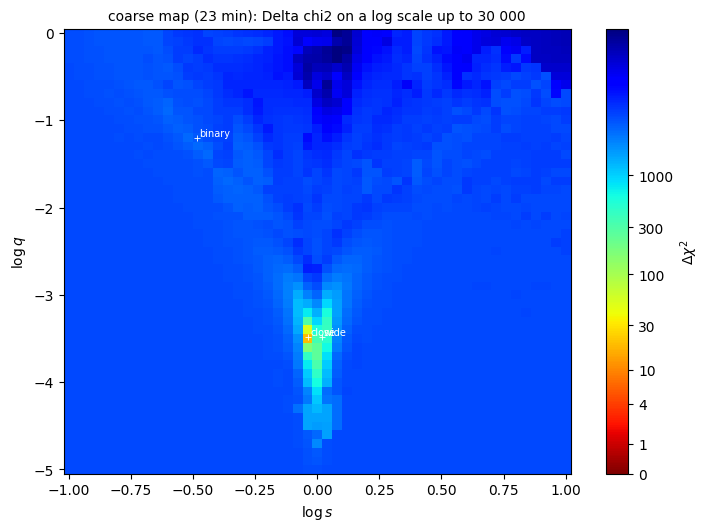

In [7]:
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def run_or_load(name, compute):
    # data/rmdc1422_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/rmdc1422_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

logs1 = np.round(np.arange(-1.0, 1.0001, 0.04), 4)
logq1 = np.round(np.arange(-5.0, 0.0001, 0.1), 4)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best_first, bin_wings=False, dchi2_cut=5.0,
                                                  log=log))
ref0 = first["fits"][0][0]
fig, ax = plt.subplots(figsize=(7, 5.2), constrained_layout=True)
figures.plot_map(map1, ax=ax, vmax=30000, chi2_ref=ref0, marks={"wide": check["wide"][3:5], "close": check["close"][3:5],
                                                                "binary": check["binary"][3:5]})
ax.set_title(f"coarse map ({map1['wall'] / 60:.0f} min): Delta chi2 on a log scale up to 30 000", fontsize=10);

The map has the V shape typical of central-caustic events: two arms, one on each side of log *s* = 0, that meet
near log *q* ≈ −3.5 and open towards larger *q*. Along the arms the central caustic keeps roughly the size the
anomaly needs, which is why they reach far: a wider separation needs a heavier companion for the same central
caustic. Only near their tips, at the planetary solutions, do they come within a few hundred of the minimum; at
*q* > 0.01 (stellar binaries) they are 1000 or more above it. At this step the two minima are hardly visible: the
lowest lattice point is 19 above the best fit.

## 6. Zooming into the V

`lenscape.maps.densify` refines boxes aligned with the coarse lattice:

* **4×** over the whole tip of the V, −0.16 ≤ log *s* ≤ 0.12 and −4.2 ≤ log *q* ≤ −2.8 (steps 0.01 × 0.025,
  29 × 57 points, **23 minutes**);
* **32×** in log *s* and 8× in log *q* (0.00125 × 0.0125) around each of the two minima (**2 minutes each**);
* **64×** × 16× (0.000625 × 0.00625) on the close minimum, to check whether it is a single minimum (**0.6 minutes**).

In [8]:
step = lambda lo, hi, x0, st: np.round(x0 + st * np.arange(int(np.ceil((lo - x0) / st - 1e-9)),
                                                           int(np.floor((hi - x0) / st + 1e-9)) + 1), 6)
dens = lambda prev, s, q, fs, fq: lenscape.maps.densify(prev, data, step(*s, -1.0, 0.04 / fs), step(*q, -5.0, 0.1 / fq),
                                                         best=best_first, bin_wings=False, log=log)
map4 = run_or_load("box_4x", lambda: dens([map1], (-0.16, 0.12), (-4.2, -2.8), 4, 4))
mapc = run_or_load("close_32x", lambda: dens([map4, map1], (-0.052, -0.024), (-3.66, -3.30), 32, 8))
mapw = run_or_load("wide_32x", lambda: dens([map4, map1], (0.006, 0.034), (-3.66, -3.30), 32, 8))
mapc64 = run_or_load("close_64x", lambda: dens([mapc, map4], (-0.0425, -0.0300), (-3.56, -3.43), 64, 16))
MAPS = [("coarse", map1), ("4x", map4), ("close 32x", mapc), ("wide 32x", mapw), ("close 64x", mapc64)]
ref = min(np.nanmin(m["chi2"]) for _, m in MAPS)
for name, m in MAPS:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:10s}: {m['chi2'].shape[0]:2d} x {m['chi2'].shape[1]:2d} points, {m['wall'] / 60:4.1f} min, lowest point "
          f"{m['chi2'][i, j] - ref:6.2f} at log s = {m['logs'][i]:+.5f}, log q = {m['logq'][j]:.4f}")

coarse    : 51 x 51 points, 23.3 min, lowest point  19.11 at log s = -0.04000, log q = -3.5000
4x        : 29 x 57 points, 22.6 min, lowest point   0.46 at log s = +0.02000, log q = -3.4750
close 32x : 22 x 29 points,  2.4 min, lowest point   3.25 at log s = -0.03750, log q = -3.4875
wide 32x  : 23 x 29 points,  1.5 min, lowest point   0.00 at log s = +0.01875, log q = -3.4875
close 64x : 21 x 21 points,  0.6 min, lowest point   3.23 at log s = -0.03750, log q = -3.4813


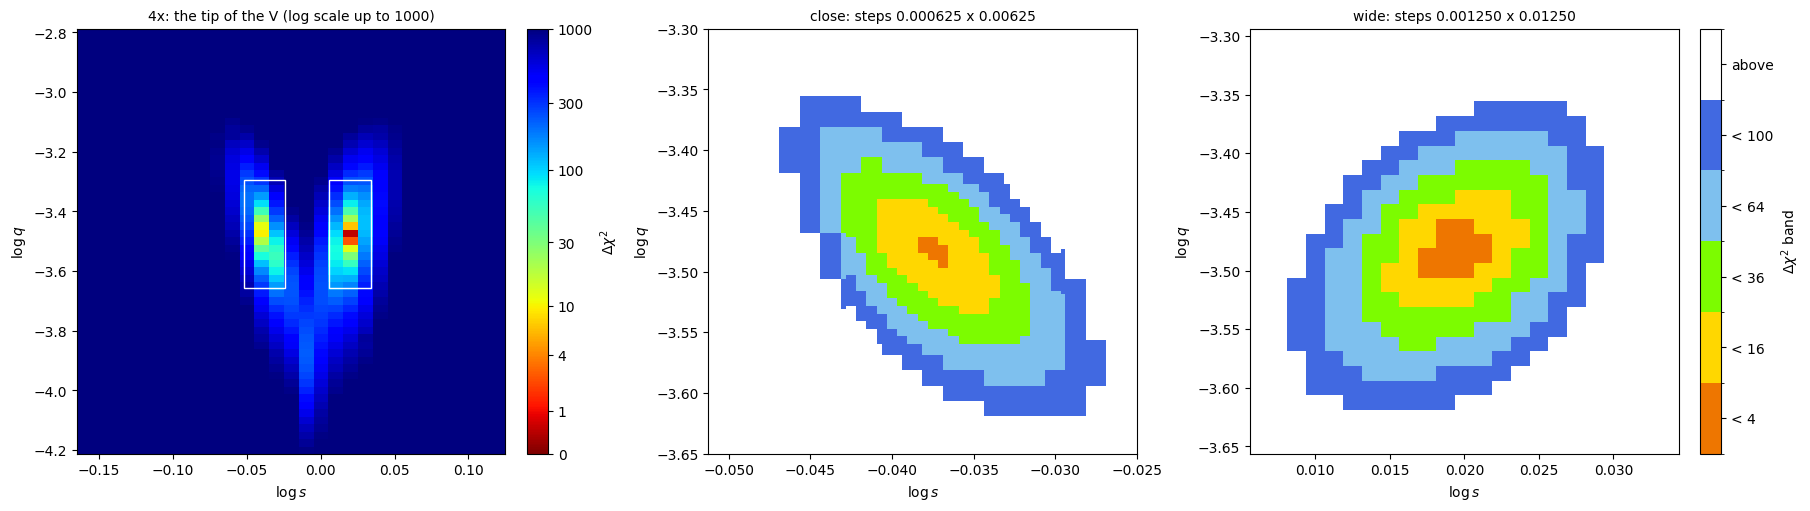

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
figures.plot_map(map4, ax=axs[0], vmax=1000, chi2_ref=ref)
for _, m in MAPS[2:4]:
    hs, hq = (m["logs"][1] - m["logs"][0]) / 2, (m["logq"][1] - m["logq"][0]) / 2
    axs[0].add_patch(plt.Rectangle((m["logs"][0] - hs, m["logq"][0] - hq), m["logs"][-1] - m["logs"][0] + 2 * hs,
                                   m["logq"][-1] - m["logq"][0] + 2 * hq, fill=False, ec="w", lw=1))
axs[0].set_title("4x: the tip of the V (log scale up to 1000)", fontsize=10)
for ax, m, name in ((axs[1], mapc64, "close"), (axs[2], mapw, "wide")):
    figures.plot_map(m, bands=(4, 16, 36, 64, 100), ax=ax, chi2_ref=ref, colorbar=(ax is axs[2]))
    ax.set_title(f"{name}: steps {m['logs'][1] - m['logs'][0]:.6f} x {m['logq'][1] - m['logq'][0]:.5f}", fontsize=10)
axs[1].set_xlim(mapc["logs"][0], mapc["logs"][-1]); axs[1].set_ylim(mapc["logq"][0], mapc["logq"][-1])
for _, m in [MAPS[2]]:                                        # the 32x close box under its 64x part
    figures.plot_map(m, bands=(4, 16, 36, 64, 100), ax=axs[1], chi2_ref=ref, colorbar=False)
figures.plot_map(mapc64, bands=(4, 16, 36, 64, 100), ax=axs[1], chi2_ref=ref, colorbar=False)
axs[1].set_xlim(mapc["logs"][0], mapc["logs"][-1]); axs[1].set_ylim(mapc["logq"][0], mapc["logq"][-1]);

At 4× the tip of the V separates into two narrow valleys, close (log *s* ≈ −0.037) and wide (≈ +0.019), joined
below log *q* ≈ −3.7 by a ridge more than 100 above the minimum. The 32× boxes resolve each into one closed,
tilted ellipse; the 64× box on the close minimum (drawn over its 32× box) shows that it is a single minimum. The
ellipses tilt in opposite directions: in the close valley a larger *s* must be paired with a smaller *q*, in the wide
valley with a larger *q*, so that the central caustic keeps its size. Nothing else on the map comes within 100.

## 7. The two solutions

Each minimum is polished with all seven parameters free, first on the binned data, then on the unbinned season.

In [10]:
best_file = "data/rmdc1422_best.json"
if RECOMPUTE or not os.path.exists(best_file):
    log("polishing the close and wide solutions")
    out = {}
    for name, m, sign in (("close", mapc64, -1), ("wide", mapw, 1)):
        i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
        x = m["pars"][i, j]
        starts = [np.array([x[0], x[1], x[2], m["logs"][i], m["logq"][j], x[3], x[4]])]
        starts += [np.array(p) for c, p in first["fits"] if np.sign(p[3]) == sign and c < 1600][:2]
        c_b, p_b = min((lenscape.fit_full(data, p, be) for p in starts), key=lambda r: r[0])
        c_s, p_s = lenscape.fit_full(season, p_b, be, rounds=2, maxfev=4000)
        out[name] = dict(p_binned=list(p_b), p_season=list(p_s))
    json.dump(out, open(best_file, "w"), indent=1)
B = json.load(open(best_file))
SOL = {n: np.array(B[n]["p_season"]) for n in ("wide", "close")}
c_w = model.chi2(be, SOL["wide"], season)
print(f"{'':6s} {'chi2':>9s} {'dchi2':>6s} {'t0':>9s} {'u0':>7s} {'tE':>6s} {'s':>7s} {'q':>9s} {'alpha':>6s} {'rho':>8s}")
for n, p in SOL.items():
    c = model.chi2(be, p, season)
    print(f"{n:6s} {c:9.2f} {c - c_w:6.2f} {p[0]:9.4f} {p[1]:7.4f} {p[2]:6.3f} {10 ** p[3]:7.4f} {10 ** p[4]:9.3e} "
          f"{p[5]:6.3f} {10 ** p[6]:8.2e}")
print(f"season data: N = {len(season)}")

            chi2  dchi2        t0      u0     tE       s         q  alpha      rho
wide     8198.18   0.00 2959.1603  0.0410 10.726  1.0454 3.280e-04  4.889 2.02e-03
close    8201.09   2.91 2959.1600  0.0410 10.735  0.9178 3.274e-04  4.889 2.04e-03
season data: N = 8155


| | wide | close |
|---|---|---|
| χ² (season, N = 8155) | 8198.2 | 8201.1 |
| *s* | 1.0454 | 0.9178 |
| *q* | 3.28 × 10⁻⁴ | 3.27 × 10⁻⁴ |
| *t*ₑ | 10.73 d | 10.74 d |
| *u*₀ | 0.0410 | 0.0410 |
| α | 4.889 rad | 4.889 rad |
| ρ | 2.0 × 10⁻³ | 2.0 × 10⁻³ |

The two solutions share every parameter except *s*. The data prefer the wide one by Δχ² = 2.9, which is not
decisive: by the usual standard (Δχ² ≳ 10) the degeneracy is **not resolved**, and both must be reported. The
product of the two separations is 0.96, not 1: both lie close to the resonant range (*s* ≈ 1), where the
close/wide symmetry of the central caustic is only approximate. That small asymmetry is all that separates them.

## 8. The light curves

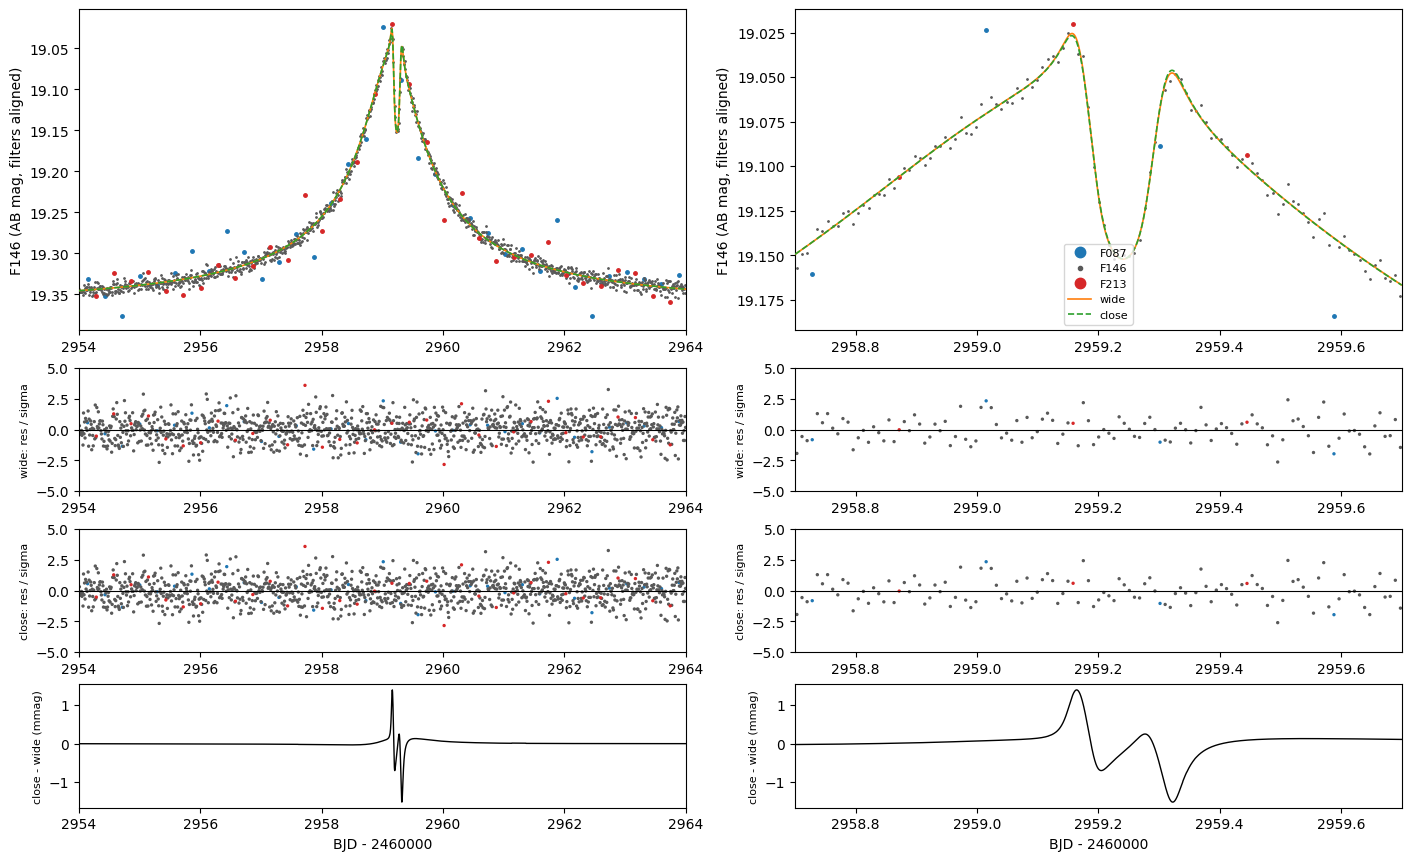

In [11]:
def plot_lc(sols, d=season, window=(2954, 2964), zoom=(2958.7, 2959.7)):
    # data of all filters aligned to F146 of the first solution; residuals of each solution; their difference
    p0 = list(sols.values())[0]
    fs, fb = model.fluxes(model.magnification(be, p0, d), d)
    k0 = d.names.index("F146")
    fig = plt.figure(figsize=(14, 8.5), constrained_layout=True)
    gs = fig.add_gridspec(2 + len(sols), 2, height_ratios=[2.6] + [1] * len(sols) + [1])
    for col, (a, b) in enumerate((window, zoom)):
        ax = fig.add_subplot(gs[0, col])
        for k, (n, c) in enumerate(zip(d.names, ["C0", "0.35", "C3"])):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            ax.plot(d.t[m], mag(fs[k0] * (d.f[m] - fb[k]) / fs[k] + fb[k0]), ".", ms=2 if n == "F146" else 5, color=c,
                    label=n, zorder=2)
        tt = np.linspace(a, b, 3000)
        for (name, p), ls in zip(sols.items(), ("-", "--")):
            f2, b2 = model.fluxes(model.magnification(be, p, d), d)
            ax.plot(tt, mag(f2[k0] * be.lc(model.clamp(p)[0], tt) + b2[k0]), ls, color="C1" if ls == "-" else "C2",
                    lw=1.2, label=name, zorder=3)
        ax.invert_yaxis(); ax.set_xlim(a, b); ax.set_ylabel("F146 (AB mag, filters aligned)")
        if col == 1:
            ax.legend(fontsize=8, markerscale=3, loc="lower center")
        for r, (name, p) in enumerate(sols.items()):
            axr = fig.add_subplot(gs[1 + r, col])
            m = (d.t > a) & (d.t < b)
            res = model.residuals(be, p, d)[m]
            axr.scatter(d.t[m], res, s=2, c=[["C0", "0.35", "C3"][i] for i in d.idx[m]])
            axr.axhline(0, color="k", lw=0.8); axr.set_xlim(a, b); axr.set_ylim(-5, 5)
            axr.set_ylabel(f"{name}: res / sigma", fontsize=8)
        axd = fig.add_subplot(gs[-1, col])
        (n1, p1), (n2, p2) = list(sols.items())[:2]
        f1, g1 = model.fluxes(model.magnification(be, p1, d), d)
        f2, g2 = model.fluxes(model.magnification(be, p2, d), d)
        diff = mag(f2[k0] * be.lc(model.clamp(p2)[0], tt) + g2[k0]) - mag(f1[k0] * be.lc(model.clamp(p1)[0], tt) + g1[k0])
        axd.plot(tt, diff * 1e3, "k", lw=1); axd.set_xlim(a, b)
        axd.set_ylabel(f"{n2} - {n1} (mmag)", fontsize=8); axd.set_xlabel("BJD - 2460000")
    return fig

plot_lc(SOL);

Both models follow the double-peaked shape at the maximum (right): a rise, the 0.1-mag dip of about two hours at
BJD′ 2959.2, and the second maximum. Their residuals look the same. The bottom panels show why the data can barely
tell them apart: the two model light curves never differ by more than 1.5 millimagnitudes, a fifth of the error of
one 12-minute F146 point at the peak (about 7 mmag). Only the sum over many points gives the wide model
its small advantage.

## 9. The caustics

wide: 1 caustic curve(s)
close: 3 caustic curve(s)


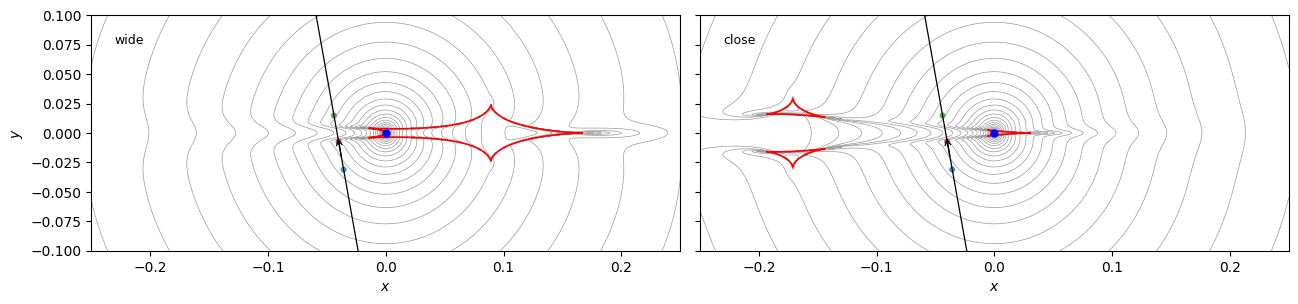

In [12]:
fig = figures.plot_geometry([SOL["wide"], SOL["close"]], labels=["wide", "close"], ncols=2, figsize=(13, 5.2),
                            extent=(-0.25, 0.25, -0.1, 0.1), t_arrow=2959.0)
for ax, (name, p) in zip(fig.axes, SOL.items()):
    x0 = caustics.lens_positions(10 ** p[3], 10 ** p[4])[0]
    for t, c in ((2958.9, "C0"), (2959.16, "C3"), (2959.4, "C2")):
        z = caustics.trajectory(p, [t])[0]
        ax.add_patch(plt.Circle((z.real - x0, z.imag), 10 ** p[6], color=c, alpha=0.7))
for name, p in SOL.items():
    print(f"{name}: {len(caustics.caustics(10 ** p[3], 10 ** p[4], 500))} caustic curve(s)")

The panels show the region around the host (at the origin; the planet lies at *x* = *s*, outside the panels). The
coloured disks are the source at BJD′ 2958.9, 2959.16 and 2959.4.

* **Wide** (*s* = 1.045): close to the Einstein ring, the central and the planetary caustic have merged into one
  *resonant* caustic, an elongated curve that stretches from the host 0.17 Einstein radii towards the planet.
* **Close** (*s* = 0.918): three caustics, a small central one at the host and two triangular planetary caustics on
  the side away from the planet, at *x* ≈ −0.17.

Yet the source sees almost the same thing in both. It passes 0.04 Einstein radii from the host on the side away
from the planet, 13 (wide) or 17 (close) source radii from the back cusp of the caustic at the host. There, behind
the host, the two geometries produce nearly the same magnification pattern: a narrow ridge running out of the
cusp, flanked by slightly demagnified troughs (the pinched contours left of the host). Crossing ridge and troughs
makes the double-peaked maximum with its sharp dip. The source never crosses a caustic; its finite size still matters (a point source is worse by up to about 40 in
χ²), but ρ is only weakly measured.

## 10. What kind of system is this?

**Measured.** In both solutions the companion has *q* = 3.28 × 10⁻⁴ of the host's mass: a third of the Jupiter–Sun
ratio, about the Saturn–Sun ratio (2.9 × 10⁻⁴). Its projected separation is *s* = 1.05 or 0.92 Einstein radii, close to
the Einstein ring; the data do not decide which. The Einstein timescale is *t*ₑ = 10.7 d.

**Physical scale (very rough).** The source is very faint: F146 = 24.0 AB (1.4 % of the baseline light), and
F087 − F213 = 2.08. With the challenge's extinction (*A* = 2.03, 0.81, 0.27 mag) it is F146₀ = 23.2 with
(F087 − F213)₀ = 0.32. At the distance of the bulge (8 kpc) it would have an absolute magnitude of about 8.7, about
4 mag fainter than the Sun in the near infrared: an M dwarf of about 0.16 solar radii (assuming the Sun's surface
brightness, as in the first example), θ⋆ ≈ 0.09 µas. With ρ = 2.0 × 10⁻³ that gives θₑ ≈ 0.045 mas, a small Einstein
radius, and μ ≈ 1.5 mas/yr.

In [13]:
theta_E = 0.09e-3 / 10 ** SOL["wide"][6]          # mas, from theta_* ~ 0.09 micro-arcsec (very rough, see text)
DS = 8.0
print(f"theta_E = {theta_E:.3f} mas, mu_rel = {theta_E / SOL['wide'][2] * 365.25:.1f} mas/yr")
print(f"{'D_L (kpc)':>9s} {'M_host (Msun)':>13s} {'M_planet (Earth)':>16s} {'a_perp wide/close (AU)':>23s}")
for DL in (4.0, 6.0, 7.0, 7.5):
    M = theta_E ** 2 / (8.144 * (1 / DL - 1 / DS))
    a = [10 ** SOL[n][3] * theta_E * DL for n in ("wide", "close")]
    print(f"{DL:9.1f} {M:13.4f} {10 ** SOL['wide'][4] * M * 332946:16.2f} {a[0]:11.2f} / {a[1]:.2f}")

theta_E = 0.045 mas, mu_rel = 1.5 mas/yr
D_L (kpc) M_host (Msun) M_planet (Earth)  a_perp wide/close (AU)
      4.0        0.0019             0.21        0.19 / 0.16
      6.0        0.0058             0.64        0.28 / 0.25
      7.0        0.0136             1.49        0.33 / 0.29
      7.5        0.0292             3.19        0.35 / 0.31


Taken at face value, such a small θₑ means a very light host or a lens close to the source: for *D*_L = 4–7.5 kpc
the host would be 0.002–0.03 M_⊙ (a few Jupiter masses to a brown dwarf) and the companion 0.2–3 Earth masses,
0.16–0.35 AU from it. This should not be over-read. ρ is measured only weakly (the source never touches a caustic),
θ⋆ from one magnitude and a solar surface brightness is uncertain by a factor of about two, and the source could be
in front of the bulge. What the light curve establishes is the mass ratio, a Saturn-like ratio, and that the
companion sits near the Einstein ring on one of two sides.

## 11. Summary

* A blind 2L1S analysis of an Experienced-tier Roman event finds the classic central-caustic degeneracy: a wide
  (*s* = 1.045) and a close (*s* = 0.918) solution with the same *q* = 3.28 × 10⁻⁴, separated by only Δχ² = 2.9. Both
  fit all 49 488 points to χ²/N = 0.996.
* The coarse map shows the V of central-caustic events from planets to stellar binaries; densified boxes at 4×, 32×
  and 64× resolve its tip into two narrow, single minima. Stellar-binary solutions are at least 1000 worse.
* The two models differ by at most 1.5 millimagnitudes, so even Roman's 12-minute photometry cannot break the
  degeneracy for this faint source.
* Not done: parallax, MCMC uncertainties, limb darkening, and a proper physical analysis (the rough scale suggests a
  low-mass host, but ρ and θ⋆ are poorly known).

**References.** Dominik, M. 1999, A&A, 349, 108. Griest, K., & Safizadeh, N. 1998, ApJ, 500, 37. Penny, M. T., et al.
2019, ApJS, 241, 3. Roman Microlensing Data Challenge 2026, RGES-PIT,
[rges-pit.org/data-challenge](https://rges-pit.org/data-challenge/).